## 1. Load the pretrained model

In [1]:
import pathlib, numpy as np, torch, pandas as pd, matplotlib.pyplot as plt
import torchxrayvision as xrv
from PIL import Image

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

model = xrv.models.DenseNet(weights='densenet121-res224-all')
model.eval()
print(f'model               : DenseNet-121')
print(f'weights             : densenet121-res224-all')
print(f'input resolution    : 224 x 224 (grayscale)')
print(f'output pathologies  : {len(model.pathologies)}')
print(f'parameters          : {sum(p.numel() for p in model.parameters()):,}')

model               : DenseNet-121
weights             : densenet121-res224-all
input resolution    : 224 x 224 (grayscale)
output pathologies  : 18
parameters          : 6,966,034


## 2. The 18 pathologies it predicts

In [2]:
pd.DataFrame({'index': range(len(model.pathologies)), 'pathology': model.pathologies}).set_index('index')

,pathology
index,
0,Atelectasis
1,Consolidation
2,Infiltration
3,Pneumothorax
4,Edema
5,Emphysema
6,Fibrosis
7,Effusion
8,Pneumonia


## 3. Run on one real chest X-ray

Uses a real IU Chest X-Ray image downloaded locally. Image is preprocessed exactly as torchxrayvision expects: grayscale, centered, resized to 224×224.

In [3]:
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
IMG_DIR = ROOT / 'datasets' / 'iu_xray' / 'images'
img_path = next(iter(sorted(IMG_DIR.glob('*.png'))))
print(f'image: {img_path.name}')

img = Image.open(img_path).convert('L')
arr = np.array(img, dtype=np.float32)
arr = xrv.datasets.normalize(arr, 255)
arr = arr[None, ...]
arr = xrv.datasets.XRayCenterCrop()(arr)
arr = xrv.datasets.XRayResizer(224)(arr)
tensor = torch.from_numpy(arr).unsqueeze(0)
with torch.no_grad():
    out = model(tensor)[0]
probs = {name: float(p) for name, p in zip(model.pathologies, out) if name}
print(f'ran inference on {img_path.name}: {len(probs)} probabilities returned')

image: 10_IM-0002-2001.dcm.png


ran inference on 10_IM-0002-2001.dcm.png: 18 probabilities returned


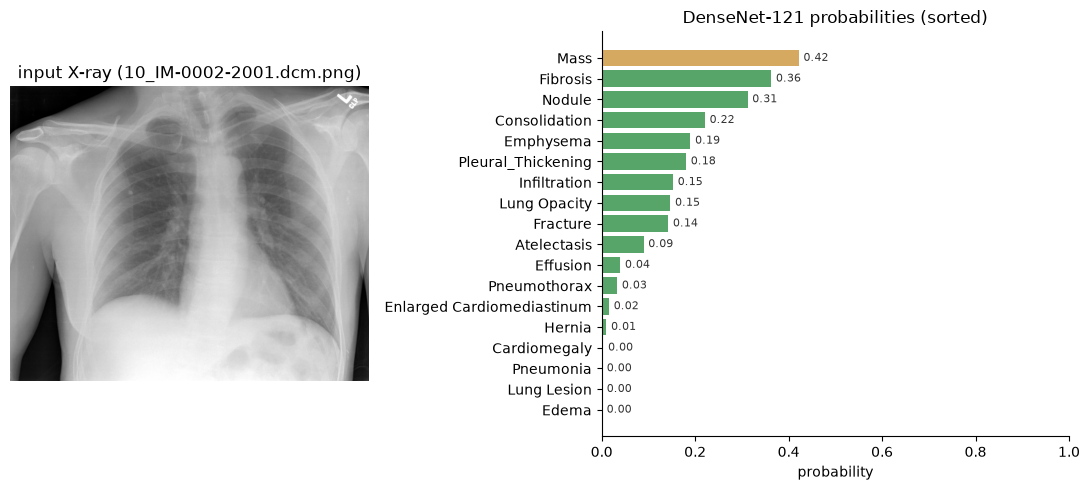

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={'width_ratios': [1, 1.3]})
ax[0].imshow(img, cmap='gray')
ax[0].set_title(f'input X-ray ({img_path.name})'); ax[0].axis('off')

sorted_probs = sorted(probs.items(), key=lambda kv: kv[1], reverse=True)
names, vals = zip(*sorted_probs)
colors = ['#CF4647' if v > 0.6 else '#D6A961' if v > 0.4 else '#58A569' for v in vals]
ax[1].barh(range(len(names)), vals, color=colors)
ax[1].set_yticks(range(len(names)), names)
ax[1].invert_yaxis()
ax[1].set_xlim(0, 1)
ax[1].set_xlabel('probability')
ax[1].set_title('DenseNet-121 probabilities (sorted)')
for i, v in enumerate(vals):
    ax[1].text(min(v + 0.01, 0.97), i, f'{v:.2f}', va='center', fontsize=8, color='#333')
plt.tight_layout(); plt.show()

In [5]:
pd.DataFrame(sorted_probs, columns=['pathology', 'probability'])\
  .assign(probability=lambda d: d.probability.round(3))\
  .head(10)

,pathology,probability
0,Mass,0.422
1,Fibrosis,0.363
2,Nodule,0.312
3,Consolidation,0.221
4,Emphysema,0.190
5,Pleural_Thickening,0.181
6,Infiltration,0.153
7,Lung Opacity,0.147
8,Fracture,0.142
9,Atelectasis,0.090
